# 10-fold genomic prediction cross-validation in the maize G2F North region
### (Lopez-Cruz et al. 2023, *Nature Communications* 14:6904 — Fig. 7-style benchmark, partial demonstration)

**Paper:** Lopez-Cruz M. *et al.* (2023) "Leveraging data from the Genomes-to-Fields Initiative to investigate genotype-by-environment interactions in maize in North America", *Nature Communications* 14:6904, https://doi.org/10.1038/s41467-023-42687-4

**Author code:** [MAIZE-HUB](https://github.com/QuantGen/MAIZE-HUB) `analysis.zip` at commit `0385ac0f705eec9f4df41873467ed388e878bd1f` — module `6_genomic_prediction` (`4_10F_CV_model.R`, `1_get_model_components.R`) and `tools/` (`get_folds.R`, `TENSOR_EVD.R`, `c_utils.c`). The authors' own R code is downloaded and executed here.

**Data:** Figshare article [22776806 v1](https://doi.org/10.6084/m9.figshare.22776806), `curated_data.zip` (155,889,345 bytes, md5 `ef16f786936e8ec0a78ad6fe3de3718b`).

**Executed scope — partial demonstration:** 10-fold cross-validation by genotype (the paper's precomputed `CV_10fold` column) for **grain yield** in the **largest single North-region year (2018)**, comparing the paper's two core models: (1) random effects `LOC+YL+H+HL` (BRR) and (2) SNP + EC + SNP×EC reaction norm (BRR with 0.975 tensor-eigen threshold). Predictive correlations (observed vs predicted yield) are reported per fold. MCMC settings are the author script's defaults `nIter=1000, burnIn=400` (the manuscript used 12000/4000; this notebook therefore reproduces the *procedure*, with noisier posterior sampling than the published figures).

**AI-assisted adaptation statement:** The authors' pipeline is R code written for an HPC/SLURM cluster, not a Colab notebook. This notebook **launches the authors' own R code** (`BGLR::BLRXy`, `get_folds.R`, `TENSOR_EVD.R` + `c_utils.c`) via `Rscript`; it is a launcher, not a re-implementation. Documented adaptations:
1. **Scope:** one North-region year (2018) instead of the full region — the authors request 60–160 GB RAM per job (their SLURM headers) vs ~12.7 GB on a free Colab CPU runtime.
2. **Memory:** `GENO.csv` (4,372 genotypes × 98,026 SNPs) is processed in column chunks; the arithmetic is identical to the authors' `scale(...)` + `tcrossprod` (full-genotype column centering).
3. **Single-level factor:** in the single-year scope the author's centered `Z.YEAR` column is exactly zero, so the YEAR fixed term is omitted — mathematically identical.

**日本語:** このノートブックは、G2F（Genomes to Fields）北米データを用いた 10 折交差検証によるゲノム予測精度比較（Lopez-Cruz et al. 2023, Fig. 7 の手法）を、著者自身の R コード（BGLR ほか）を Colab CPU 上で実行して部分的に再現します。範囲は北地域の最大年（2018年）・収量（yield）・2 モデル（ランダム効果モデルと SNP+EC+SNP×EC 反応規範モデル）です。著者の HPC 用コードをメモリ制約に合わせて一部適応させており、その内容は各セルで説明します。

## Runtime selection and how to run

**Select a CPU runtime** (Runtime → Change runtime type → CPU, standard memory). The method is BGLR Bayesian linear regression in R — a CPU-only C/Fortran workload with no GPU path in the authors' pipeline, so no GPU is used or required.

**Run all** (Runtime → Run all). Expected total time on a free Colab CPU runtime: ≈ **50–80 minutes** (setup+download ≈ 5 min, components ≈ 5 min, 10 folds × 2 models ≈ 100–120 s per fit measured in the 2026-10-24 diagnostic probe on this VM type). Download volume ≈ 1.1 GB (curated_data.zip + analysis.zip). Per-fold results are printed as they complete and saved to `/content/10F_CV_results.csv`.

**日本語:** CPU ランタイムを選択して「すべてのセルを実行」してください。BGLR は CPU 専用の R パッケージで、GPU パスは著者パイプラインに存在しません。所要時間の目安は合計 50〜80 分、ダウンロードは約 1.1 GB です。

In [ ]:
import subprocess, sys
print("Python:", sys.version)
r = subprocess.run(["Rscript", "--version"], capture_output=True, text=True, timeout=120)
print(r.stderr.strip() or r.stdout.strip())
assert r.returncode == 0, "Rscript not available on this runtime (Colab CPU images include R)."
print("environment check done")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Rscript (R) version 4.6.1 (2026-06-24)
environment check done


### Install R dependencies

The notebook needs the authors' R packages **BGLR** (Bayesian genomic linear regression, compiles its C sources) and **data.table** (fast CSV reading for GENO.csv). Both are installed from CRAN inside the notebook. On the 2026-10-24 diagnostic probe this took ≈ 20 s (prebuilt toolchain available).

**日本語:** 著者パイプラインが使用する R パッケージ BGLR と data.table を CRAN からインストールします（診断プローブでは約 20 秒）。

In [ ]:
import subprocess, time
t = time.time()
cmd = ('ip <- rownames(installed.packages()); '
       'for (p in c("BGLR","data.table")) if (!p %in% ip) install.packages(p, repos="https://cloud.r-project.org"); '
       'cat("BGLR", as.character(packageVersion("BGLR")), " | data.table ", as.character(packageVersion("data.table")), "\n")')
r = subprocess.run(["Rscript", "-e", cmd], capture_output=True, text=True, timeout=2400)
print(r.stdout[-2000:]); print(r.stderr[-1500:])
assert r.returncode == 0, "R package installation failed"
print("install secs", round(time.time() - t, 1))

e-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c util_plink.c -o util_plink.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG      -I. -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c util_sample_cross.c -o util_sample_cross.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG      -I. -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fsta

### Download and verify the curated G2F data (Figshare 22776806 v1)

`curated_data.zip` is fetched through Figshare's public record API and verified against the record's md5 before extraction. Expected contents: `data/{PHENO,GENO,ECOV,MAP,...}.csv`. All dataset bytes stay on the Colab VM.

**日本語:** Figshare の公開記録 API から curated_data.zip を取得し、記録の md5 検証後に展開します。データはすべて Colab VM 上に置かれます。

In [ ]:
import urllib.request, json, hashlib, zipfile, os, time
os.makedirs('/content/src', exist_ok=True)
d = json.load(urllib.request.urlopen(urllib.request.Request('https://api.figshare.com/v2/articles/22776806'), timeout=60))
f = [x for x in d['files'] if x['name'] == 'curated_data.zip'][0]
print('figshare record 22776806 file:', f['name'], f['size'], 'bytes, md5', f['computed_md5'])
if not os.path.exists('/content/src/curated_data.zip'):
    t = time.time()
    urllib.request.urlretrieve(f['download_url'], '/content/src/curated_data.zip')
    print('downloaded in', round(time.time() - t, 1), 's')
h = hashlib.md5(open('/content/src/curated_data.zip', 'rb').read()).hexdigest()
assert h == f['computed_md5'], f'md5 mismatch: {h}'
print('md5 verified:', h)
if not os.path.exists('/content/data/data/PHENO.csv'):
    zipfile.ZipFile('/content/src/curated_data.zip').extractall('/content/data')
print(sorted(os.listdir('/content/data/data')))

figshare record 22776806 file: curated_data.zip 155889345 bytes, md5 ef16f786936e8ec0a78ad6fe3de3718b


downloaded in 1.7 s


md5 verified: ef16f786936e8ec0a78ad6fe3de3718b


['ECOV.csv', 'ECOV_KL.csv', 'ECOV_layered.csv', 'ECOV_period.csv', 'GENO.csv', 'MAP.csv', 'PHENO.csv']


### Download the authors' code archive (pinned commit) and extract the R tools

`analysis.zip` is retrieved from the pinned MAIZE-HUB commit `0385ac0f...` and only `pipeline_analysis/tools/` (R sources + C source) is extracted to `/content/mh/tools/`. The authors' `4_10F_CV_model.R` is shown in full below for provenance. The zip's prebuilt `c_utils.so` is recompiled from the bundled `c_utils.c` for determinism.

**日本語:** 著者リポジトリの指定コミットから analysis.zip を取得し、tools/ の R・C ソースのみ展開します。著者の 4_10F_CV_model.R は出所確認のため全文を表示します。

In [ ]:
import urllib.request, zipfile, os
COMMIT = '0385ac0f705eec9f4df41873467ed388e878bd1f'
url = f'https://github.com/QuantGen/MAIZE-HUB/raw/{COMMIT}/analysis.zip'
if not os.path.exists('/content/src/analysis.zip'):
    urllib.request.urlretrieve(url, '/content/src/analysis.zip')
z = zipfile.ZipFile('/content/src/analysis.zip')
os.makedirs('/content/mh/tools', exist_ok=True)
n = 0
for name in z.namelist():
    if name.startswith('pipeline_analysis/tools/') and name.endswith(('.R', '.c')):
        open('/content/mh/tools/' + os.path.basename(name), 'wb').write(z.read(name)); n += 1
print('extracted', n, 'tool files:', sorted(os.listdir('/content/mh/tools')))

extracted 6 tool files: ['Functions.R', 'TENSOR_EVD.R', 'c_utils.c', 'ecov_utils.R', 'get_folds.R', 'get_variance.R']


### Provenance: the authors' 10-fold CV script (`4_10F_CV_model.R`)

The full author script is printed from the pinned archive. Key facts verified from this source: folds come from the **precomputed `CV_10fold` column** of PHENO.csv; ETA terms use `model.matrix(...) |> scale(center=TRUE, scale=FALSE)`; prediction is `mu + Σ_k Z[tst,] %*% fm$ETA[[k]]$b`; script defaults are `nIter=1000, burnIn=400`.

**日本語:** 著者のスクリプトを指定アーカイブから全文表示します（fold 定義、ETA 構成、予測式、MCMC 既定値の根拠）。

In [ ]:
import zipfile
z = zipfile.ZipFile('/content/src/analysis.zip')
p = [n for n in z.namelist() if n.endswith('4_10F_CV_model.R')][0]
print('===', p, '===')
print(z.read(p).decode())

=== pipeline_analysis/6_genomic_prediction/code/4_10F_CV_model.R ===
#!/usr/bin/env Rscript
#!/mnt/research/quantgen/tools/scripts/Rscript_login_shell_wrapper
#SBATCH --job-name=10F_CV
#SBATCH --output=../log/%x_%A_%a
#SBATCH --time=03:59:00
#SBATCH --cpus-per-task=1
#SBATCH --mem-per-cpu=60G
#SBATCH --array=1-120

rm(list=ls())

setwd("/mnt/research/quantgen/projects/G2F/resource_paper/pipeline_analysis")

# Load functions
library(BGLR)
source("tools/get_folds.R")

job <- as.integer(Sys.getenv("SLURM_ARRAY_TASK_ID", "1"))

folds <- as.character(1:10)
traits <- c("yield","anthesis","silking","ASI")

models <- c("YEAR+LOC+YL+H+HL",
            "SNP+EC+SNPxEC",
            "YEAR+LOC+YL+H+HL+GPC+WPC")

region <- c("North","South")[2]  # Select a region
nPC <- 5

JOBS <- expand.grid(fold=folds,trait=traits,model=models)
model <- as.vector(JOBS[job,"model"])
trait <- as.vector(JOBS[job,"trait"])
fold <- as.vector(JOBS[job,"fold"])

pheno <- read.csv("../data/PHENO.csv")

# Get CV folds
if(!

### Input preview: PHENO.csv, North region, scope year

Before any modeling, this cell previews the actual phenotype table: region/year structure, the deterministic scope year (largest North year), the genotype CV-fold assignment in scope, and yield distribution. This is observed data content, not interpretation.

**日本語:** モデル化の前に、実際のフェノタイム表（地域・年構成、スコープ年、fold 構成、収量分布）を確認します。

In [ ]:
import pandas as pd
p = pd.read_csv('/content/data/data/PHENO.csv', low_memory=False)
north = p[p['region'] == 'North'].copy()
print('PHENO records:', len(p), '| North:', len(north))
print(north['year'].value_counts().sort_index())
counts = north['year'].astype(str).value_counts()
scope_year = counts.idxmax()
print('\nScope year (largest North year):', scope_year)
sub = north[north['year'].astype(str) == scope_year]
print('records', len(sub), '| genotypes', sub['genotype'].nunique(),
      '| year_locs', sub['year_loc'].nunique(), '| CV folds:', sorted(sub['CV_10fold'].unique()))
print('\nYield (t/ha) summary in scope year:')
print(sub['yield'].describe())
print('\nFirst rows of the scope-year table:')
sub[['year_loc', 'genotype', 'CV_10fold', 'yield']].head()

PHENO records: 78686 | North: 59069
year
2014     5306
2015     5514
2016     6816
2017     5237
2018    11189
2019    10502
2020     6476
2021     8029
Name: count, dtype: int64

Scope year (largest North year): 2018
records 11189 | genotypes 1031 | year_locs 13 | CV folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Yield (t/ha) summary in scope year:
count    11189.000000
mean         9.932795
std          2.402855
min          1.758188
25%          8.297566
50%          9.998006
75%         11.641952
max         17.989254
Name: yield, dtype: float64

First rows of the scope-year table:


,year_loc,genotype,CV_10fold,yield
28432,2018-IAH2,CG119/CG108,5,4.685780
28433,2018-IAH2,PHW65_MOG_0170/LH195,9,7.848761
28434,2018-IAH2,PHW65_MOG_0041/LH195,10,13.936823
28435,2018-IAH2,PHW65_MOG_0163/LH195,1,10.784514
28436,2018-IAH2,PHW65_MOG_0217/LH195,2,7.766532


### Build the model components (G_PC, W_PC, SNPxEC) with the authors' method

This cell writes `build_components.R`, which reproduces the authors' component pipeline for the scope year: the genomic relationship matrix **G** (full-genotype column centering — computed in memory-lean column chunks with identical arithmetic), its eigen decomposition **G_PC**, the env-covariate kernel **WWt** (full `scale(ECOV)` crossproduct, region submatrix renormalized, `HI30_` columns dropped) and **W_PC**, and finally the **SNP×EC** tensor eigen decomposition using the authors' `TENSOR_EVD.R` + `c_utils` C code with their threshold **0.975**. Results are cached to `/content/mh/comps_scope.rds`.

**日本語:** 著者の手法に従い、ゲノム関係行列 G（全遺伝子型での中心化を列チャンクで同一計算）、その固有分解 G_PC、環境共変量カーネル W_PC、そして著者の TENSOR_EVD（閾値 0.975）による SNP×EC テンソル固有分解を作成し、キャッシュします。

In [ ]:
open('/content/mh/build_components.R', 'w').write('# Adapted from MAIZE-HUB 1_get_model_components.R + 1_get_G_matrix_PC.R + 1_get_WWt_matrix_PC.R\n# (commit 0385ac0f705eec9f4df41873467ed388e878bd1f) for the single-year Colab scope.\n# Memory adaptation: GENO.csv (4372 x 98026) is processed in column chunks; the arithmetic is\n# identical to the author\'s scale(geno, center=TRUE, scale=FALSE) + tcrossprod because column\n# centering uses means over ALL genotypes and crossproducts accumulate additively over column blocks.\nlibrary(data.table)\nt0 <- Sys.time()\n\npheno <- read.csv("/content/data/data/PHENO.csv")\nstopifnot(!any(is.na(pheno$CV_10fold)))          # author uses the precomputed CV_10fold column\nnorth <- pheno[pheno$region == "North", ]\nnorth$year <- as.character(north$year)\ntt <- sort(table(north$year), decreasing = TRUE)  # deterministic scope: largest North year\nprint(tt)\nyr <- names(tt)[1]\ncat("SCOPE YEAR:", yr, "\\n")\nsub <- north[north$year == yr, ]\nsub$year     <- factor(sub$year)\nsub$location <- factor(as.character(sub$location))\nsub$year_loc <- factor(as.character(sub$year_loc))\nsub$genotype <- factor(as.character(sub$genotype))\nsub$gen_loc  <- factor(paste0(sub$genotype, ":", sub$location))\ncat("records", nrow(sub), "genotypes", nlevels(sub$genotype),\n    "year_locs", nlevels(sub$year_loc), "gen_loc levels", nlevels(sub$gen_loc), "\\n")\n\n## ---- G: genomic relationship matrix (author: tcrossprod of centered genotypes) ----\ngpath <- "/content/data/data/GENO.csv"\nhdr <- names(fread(gpath, nrow = 0)); idc <- hdr[1]; snpcols <- hdr[-1]\nmeans <- setNames(numeric(length(snpcols)), snpcols)\nchunk <- 20000\nfor (i in seq(1, length(snpcols), by = chunk)) {          # pass 1: column means (all genotypes)\n  cc <- snpcols[i:min(i + chunk - 1, length(snpcols))]\n  m  <- fread(gpath, select = c(idc, cc))\n  mm <- as.matrix(m[, cc, with = FALSE])\n  stopifnot(!any(is.na(mm)))                               # author code has no NA handling\n  means[cc] <- colMeans(mm)\n  rm(m, mm); invisible(gc())\n}\nng <- levels(sub$genotype)\nG0 <- matrix(0, length(ng), length(ng), dimnames = list(ng, ng))\nfor (i in seq(1, length(snpcols), by = chunk)) {           # pass 2: accumulate crossproducts\n  cc <- snpcols[i:min(i + chunk - 1, length(snpcols))]\n  m  <- fread(gpath, select = c(idc, cc))\n  ids <- m[[idc]]; keep <- ids %in% ng\n  Xc <- as.matrix(m[keep, cc, with = FALSE])\n  Xc <- sweep(Xc, 2, means[cc], "-")\n  ix <- match(ids[keep], ng)\n  G0[ix, ix] <- G0[ix, ix] + tcrossprod(Xc)\n  rm(m, Xc); invisible(gc())\n}\nG0 <- G0 / mean(diag(G0))                                  # author\'s region-subset normalization\ncat("G0", dim(G0), format(Sys.time() - t0), "\\n")\n\n## ---- W_PC: env covariate kernel PCs (author-exact: full-scale WWt, region submatrix) ----\nECOV <- read.csv("/content/data/data/ECOV.csv", row.names = 1)\nECOV <- ECOV[, -grep("HI30_", colnames(ECOV))]             # author drops HI30_ covariates\nstopifnot(!any(is.na(ECOV)))\nWWt  <- tcrossprod(scale(ECOV)); WWt <- WWt / mean(diag(WWt))\nyl   <- levels(sub$year_loc)\nWWt0 <- WWt[yl, yl]; WWt0 <- WWt0 / mean(diag(WWt0))\neW <- eigen(WWt0, symmetric = TRUE)\nrownames(eW$vectors) <- rownames(WWt0)                     # author sets rownames before sweep\njx <- which(eW$values > 1e-8)\nW_PC <- sweep(eW$vectors[, jx], 2, sqrt(eW$values[jx]), "*")\ncat("W_PC", dim(W_PC), "\\n")\nrm(ECOV, WWt); invisible(gc())\n\n## ---- G_PC: eigen decomposition of the region G (author-exact) ----\neG <- eigen(G0, symmetric = TRUE)\nrownames(eG$vectors) <- rownames(G0)\nix <- which(eG$values > 1e-8)\nG_PC <- sweep(eG$vectors[, ix], 2, sqrt(eG$values[ix]), "*")\ncat("G_PC", dim(G_PC), "\\n")\n\n## ---- SNPxEC: tensor (Hadamard) product eigen decomposition via the authors\' C code ----\nsource("/content/mh/tools/TENSOR_EVD.R")\ntmp <- TENSOR.EVD(G0, WWt0, sub$genotype, sub$year_loc, 0.975,\n                  path = "/content/mh/tools", verbose = TRUE)\nSNPxEC <- sweep(tmp$vectors, 2, sqrt(tmp$values), "*")\ncat("SNPxEC", dim(SNPxEC), "totalVar", tmp[[3]], "\\n")\n\nsaveRDS(list(sub = sub, G_PC = G_PC, W_PC = W_PC, SNPxEC = SNPxEC, yr = yr),\n        "/content/mh/comps_scope.rds")\ncat("COMPONENTS DONE", format(Sys.time() - t0), "\\n")')
print('build_components.R written,', len(open('/content/mh/build_components.R').read()), 'bytes')

build_components.R written, 4129 bytes


### Compile the authors' C utility and run the component build

`R CMD SHLIB c_utils.c` compiles the authors' tensor-eigen C routine (≈ 1 min), then `build_components.R` runs (≈ 4–6 min: two chunked passes over the 934 MB GENO.csv, eigen decompositions, tensor EVD). The diagnostic probe measured ≈ 4.1 min on this VM type.

**日本語:** 著者の C ルーチンをコンパイルし、成分構築スクリプトを実行します（診断プローブ実測 約 4.1 分）。

In [ ]:
import subprocess, time
r = subprocess.run(['R', 'CMD', 'SHLIB', 'c_utils.c', '-o', 'c_utils.so'],
                   cwd='/content/mh/tools', capture_output=True, text=True, timeout=600)
assert r.returncode == 0, r.stderr[-1000:]
print('c_utils.so compiled')
t = time.time()
r = subprocess.run(['Rscript', '/content/mh/build_components.R'],
                   capture_output=True, text=True, timeout=3600)
print(r.stdout[-4000:]); print(r.stderr[-2000:])
assert r.returncode == 0, 'component build failed'
print('components secs', round(time.time() - t, 1))

c_utils.so compiled



 2018  2019  2021  2016  2020  2015  2014  2017 
11189 10502  8029  6816  6476  5514  5306  5237 
SCOPE YEAR: 2018 
records 11189 genotypes 1031 year_locs 13 gen_loc levels 6900 
G0 1031 1031 3.381364 mins 
W_PC 13 13 
G_PC 1031 1031 
 Calculating tensor variances (n=1031 x 13=13403) ...
 Selected 3326 tensor eigenvectors explaining 97.5 percent of the variance=11477.508521
 Obtaining tensor eigenvectors ...
 Done!
SNPxEC 11189 3326 totalVar 11477.51 
COMPONENTS DONE 3.644075 mins 


Attaching package: ‘data.table’

The following object is masked from ‘package:base’:

    %notin%


components secs 219.4


### 10-fold cross-validation: both models, per fold

This cell writes `cv_fold.R` — the authors' `4_10F_CV_model.R` logic for one fold (mirroring their SLURM array job): fit each model with `BLRXy` on the training folds, predict the held-out fold with the authors' formula `mu + Σ_k Z[tst,] %*% b`, and report the predictive correlation. Model 1 is the random-effects benchmark (`LOC+YL+H+HL`, BRR); model 2 is the SNP+EC reaction norm with the SNP×EC tensor components. `nIter=1000, burnIn=400` are the author script's defaults.

**日本語:** 著者の fold ごとジョブ（SLURM アレイ相当）を再現する cv_fold.R を作成します。学習 fold で BLRXy を適合し、保留 fold を著者の式で予測して相関を報告します。

In [ ]:
open('/content/mh/cv_fold.R', 'w').write('# Adapted from MAIZE-HUB 6_genomic_prediction/code/4_10F_CV_model.R\n# (commit 0385ac0f705eec9f4df41873467ed388e878bd1f), one SLURM array job == one fold here.\n# Models: YEAR+LOC+YL+H+HL (random effects) and SNP+EC+SNPxEC (reaction norm).\n# Single-year scope: the author\'s Z.YEAR is a centered constant column (exactly zero), so the\n# YEAR fixed term is omitted - mathematically identical to the author\'s centered matrix.\n# Prediction follows the author\'s formula: yHat = mu + sum_k Z[tst,] %*% fm$ETA[[k]]$b.\n# Script defaults nIter=1000, burnIn=400 are kept (the manuscript used 12000/4000).\nlibrary(BGLR)\nfold <- commandArgs(trailingOnly = TRUE)[1]\ncat("BGLR", as.character(packageVersion("BGLR")), "| fold", fold, "\\n")\n\nC    <- readRDS("/content/mh/comps_scope.rds")\nsub  <- C$sub; G_PC <- C$G_PC; W_PC <- C$W_PC; SNPxEC <- C$SNPxEC\ny    <- sub$yield                                   # grain yield (t/ha), no missing values\nfoldv <- as.character(sub$CV_10fold)                # precomputed genotype folds from PHENO.csv\ntst <- which(foldv == fold); trn <- which(foldv != fold)\ncat("trn", length(trn), "tst", length(tst), "\\n")\n\nZ.LOC = scale(as.matrix(model.matrix(~ location - 1, data = sub)), center = TRUE, scale = FALSE)\nZ.YL  = scale(as.matrix(model.matrix(~ year_loc - 1, data = sub)), center = TRUE, scale = FALSE)\nZ.H   = scale(as.matrix(model.matrix(~ genotype - 1, data = sub)), center = TRUE, scale = FALSE)\nZ.HL  = scale(as.matrix(model.matrix(~ gen_loc - 1,  data = sub)), center = TRUE, scale = FALSE)\n\nt0f <- Sys.time()\nETA1 <- list(LOC=list(X=Z.LOC[trn,],model=\'BRR\',saveEffects=FALSE),\n             YL =list(X=Z.YL[trn,], model=\'BRR\',saveEffects=FALSE),\n             H  =list(X=Z.H[trn,],  model=\'BRR\',saveEffects=FALSE),\n             HL =list(X=Z.HL[trn,], model=\'BRR\',saveEffects=FALSE))\nfm <- BLRXy(y = y[trn], ETA = ETA1, nIter = 1000, burnIn = 400, verbose = FALSE)\nnames(fm$ETA) <- names(ETA1)      # BLRXy does not keep ETA names; the author script restores them\nsecs1 <- as.numeric(Sys.time() - t0f, units = "secs")\npred1 <- as.vector(fm$mu + Z.LOC[tst,] %*% fm$ETA$LOC$b + Z.YL[tst,] %*% fm$ETA$YL$b +\n                               Z.H[tst,]  %*% fm$ETA$H$b   + Z.HL[tst,] %*% fm$ETA$HL$b)\ncat(sprintf("RESULT\\tfold=%s\\tmodel=RE\\tcor=%.6f\\tsecs=%.1f\\n",\n            fold, cor(y[tst], pred1), secs1))\n\nSNP <- G_PC[as.character(sub$genotype), ]   # records x G_PC columns\nEC  <- W_PC[as.character(sub$year_loc), ]   # records x W_PC columns\nt0f <- Sys.time()\nETA2 <- list(SNP   =list(X=SNP[trn,],    model=\'BRR\',saveEffects=FALSE),\n             EC    =list(X=EC[trn,],     model=\'BRR\',saveEffects=FALSE),\n             SNPxEC=list(X=SNPxEC[trn,], model=\'BRR\',saveEffects=FALSE))\nfm2 <- BLRXy(y = y[trn], ETA = ETA2, nIter = 1000, burnIn = 400, verbose = FALSE)\nnames(fm2$ETA) <- names(ETA2)\nsecs2 <- as.numeric(Sys.time() - t0f, units = "secs")\npred2 <- as.vector(fm2$mu + SNP[tst,]    %*% fm2$ETA$SNP$b    + EC[tst,]  %*% fm2$ETA$EC$b +\n                              SNPxEC[tst,] %*% fm2$ETA$SNPxEC$b)\ncat(sprintf("RESULT\\tfold=%s\\tmodel=SNP_EC_SNPxEC\\tcor=%.6f\\tsecs=%.1f\\n",\n            fold, cor(y[tst], pred2), secs2))\ncat("FOLD DONE", fold, "\\n")')
print('cv_fold.R written,', len(open('/content/mh/cv_fold.R').read()), 'bytes')

cv_fold.R written, 3181 bytes


### Run the 10-fold CV (≈ 35–60 min)

Each fold fits both models (≈ 100–120 s per fit measured in the diagnostic probe). Results print per fold and are collected into `/content/10F_CV_results.csv`. If a fold fails, the cell stops with the R error visible rather than continuing silently.

**日本語:** 10 fold × 2 モデルを実行します（1 fit あたり診断実測 100〜120 秒）。結果は fold ごとに表示され、CSV に保存されます。

In [ ]:
import subprocess, time, pandas as pd
rows = []
for fold in range(1, 11):
    t = time.time()
    r = subprocess.run(['Rscript', '/content/mh/cv_fold.R', str(fold)],
                       capture_output=True, text=True, timeout=3600)
    print(f'--- fold {fold} (wall {round(time.time() - t, 1)} s) ---')
    print('\n'.join(line for line in r.stdout.splitlines()
                    if line.startswith(('BGLR', 'trn', 'RESULT', 'FOLD'))))
    if r.returncode != 0:
        print(r.stderr[-2000:]); raise RuntimeError(f'fold {fold} failed')
    for line in r.stdout.splitlines():
        if line.startswith('RESULT'):
            kv = dict(x.split('=') for x in line.split('\t')[1:])
            rows.append({'fold': int(kv['fold']), 'model': kv['model'],
                         'cor': float(kv['cor']), 'fit_secs': float(kv['secs'])})
res = pd.DataFrame(rows).sort_values(['fold', 'model'])
res.to_csv('/content/10F_CV_results.csv', index=False)
print('saved /content/10F_CV_results.csv with', len(res), 'rows')
res

--- fold 1 (wall 118.7 s) ---
BGLR 1.1.4 | fold 1 
trn 10158 tst 1031 
RESULT	fold=1	model=RE	cor=0.646122	secs=83.4
RESULT	fold=1	model=SNP_EC_SNPxEC	cor=0.713636	secs=27.5
FOLD DONE 1 


--- fold 2 (wall 116.5 s) ---
BGLR 1.1.4 | fold 2 
trn 9929 tst 1260 
RESULT	fold=2	model=RE	cor=0.651508	secs=80.5
RESULT	fold=2	model=SNP_EC_SNPxEC	cor=0.685752	secs=25.9
FOLD DONE 2 


--- fold 3 (wall 114.5 s) ---
BGLR 1.1.4 | fold 3 
trn 10005 tst 1184 
RESULT	fold=3	model=RE	cor=0.633544	secs=80.9
RESULT	fold=3	model=SNP_EC_SNPxEC	cor=0.682369	secs=25.3
FOLD DONE 3 


--- fold 4 (wall 113.7 s) ---
BGLR 1.1.4 | fold 4 
trn 10272 tst 917 
RESULT	fold=4	model=RE	cor=0.636872	secs=80.5
RESULT	fold=4	model=SNP_EC_SNPxEC	cor=0.738531	secs=25.2
FOLD DONE 4 


--- fold 5 (wall 114.5 s) ---
BGLR 1.1.4 | fold 5 
trn 10066 tst 1123 
RESULT	fold=5	model=RE	cor=0.634341	secs=81.3
RESULT	fold=5	model=SNP_EC_SNPxEC	cor=0.729217	secs=25.2
FOLD DONE 5 


...

--- fold 7 (wall 126.1 s) ---
BGLR 1.1.4 | fold 7 
trn 10159 tst 1030 
RESULT	fold=7	model=RE	cor=0.637316	secs=89.7
RESULT	fold=7	model=SNP_EC_SNPxEC	cor=0.710493	secs=28.3
FOLD DONE 7 


--- fold 8 (wall 120.0 s) ---
BGLR 1.1.4 | fold 8 
trn 9991 tst 1198 
RESULT	fold=8	model=RE	cor=0.682905	secs=83.9
RESULT	fold=8	model=SNP_EC_SNPxEC	cor=0.729472	secs=26.8
FOLD DONE 8 


--- fold 9 (wall 120.2 s) ---
BGLR 1.1.4 | fold 9 
trn 10020 tst 1169 
RESULT	fold=9	model=RE	cor=0.646585	secs=84.4
RESULT	fold=9	model=SNP_EC_SNPxEC	cor=0.690835	secs=26.1
FOLD DONE 9 


--- fold 10 (wall 120.8 s) ---
BGLR 1.1.4 | fold 10 
trn 9957 tst 1232 
RESULT	fold=10	model=RE	cor=0.668850	secs=84.5
RESULT	fold=10	model=SNP_EC_SNPxEC	cor=0.715662	secs=27.5
FOLD DONE 10 
saved /content/10F_CV_results.csv with 20 rows


,fold,model,cor,fit_secs
0,1,RE,0.646122,83.4
1,1,SNP_EC_SNPxEC,0.713636,27.5
2,2,RE,0.651508,80.5
3,2,SNP_EC_SNPxEC,0.685752,25.9
4,3,RE,0.633544,80.9
5,3,SNP_EC_SNPxEC,0.682369,25.3
6,4,RE,0.636872,80.5
7,4,SNP_EC_SNPxEC,0.738531,25.2
8,5,RE,0.634341,81.3
9,5,SNP_EC_SNPxEC,0.729217,25.2


### Results: predictive correlations per fold

The table shows observed-vs-predicted yield correlations for each CV fold and model, with per-model means. In the paper's Fig. 7, the reaction-norm model (SNP+EC+SNPxEC) is compared against the random-effects benchmark across traits and regions; this notebook reproduces that comparison's **procedure** on one North year.

**日本語:** fold ごとの予測相関（観測値 vs 予測値）をモデル別に表示します。

In [ ]:
import pandas as pd
res = pd.read_csv('/content/10F_CV_results.csv')
piv = res.pivot(index='fold', columns='model', values='cor')
piv.columns = ['Random effects (LOC+YL+H+HL, BRR)' if c == 'RE' else 'SNP + EC + SNPxEC (BRR)' for c in piv.columns]
print(piv.round(4).to_string())
print('\nMean predictive correlation:')
print(res.groupby('model')['cor'].agg(['mean', 'std', 'count']).round(4))

      Random effects (LOC+YL+H+HL, BRR)  SNP + EC + SNPxEC (BRR)
fold                                                            
1                                0.6461                   0.7136
2                                0.6515                   0.6858
3                                0.6335                   0.6824
4                                0.6369                   0.7385
5                                0.6343                   0.7292
6                                0.6567                   0.7048
7                                0.6373                   0.7105
8                                0.6829                   0.7295
9                                0.6466                   0.6908
10                               0.6688                   0.7157

Mean predictive correlation:
                 mean     std  count
model                               
RE             0.6495  0.0162     10
SNP_EC_SNPxEC  0.7101  0.0193     10


### Plot: per-fold predictive accuracy by model

A bar graph of per-fold correlations with mean markers, generated here from the actual notebook results (this visualization is created for this notebook; it is not a figure from the paper). This PNG is also the notebook's saved preview.

**日本語:** 実行結果から fold 別の予測精度棒グラフを作成します（本ノートブック独自の可視化であり、論文の図ではありません）。

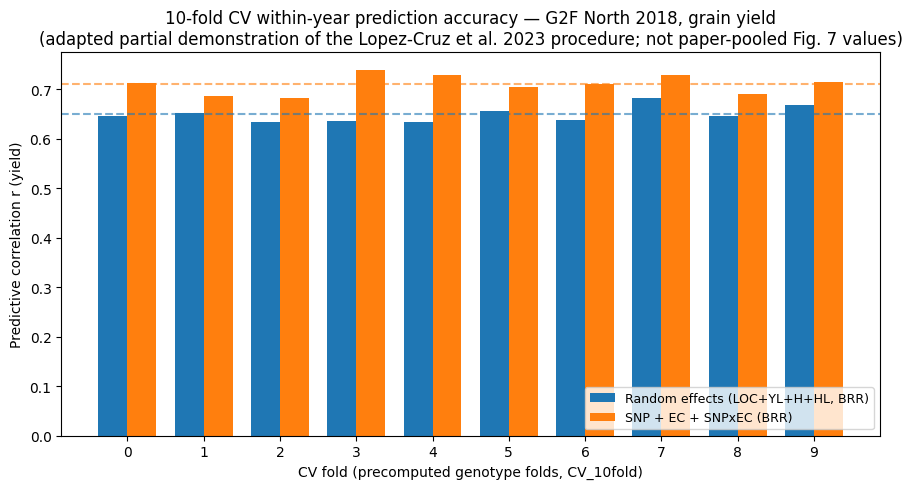

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
res = pd.read_csv('/content/10F_CV_results.csv')
piv = res.pivot(index='fold', columns='model', values='cor')
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(piv)); w = 0.38
names = {'RE': 'Random effects (LOC+YL+H+HL, BRR)', 'SNP_EC_SNPxEC': 'SNP + EC + SNPxEC (BRR)'}
for i, m in enumerate(['RE', 'SNP_EC_SNPxEC']):
    ax.bar(x + (i - 0.5) * w, piv[m], width=w, label=names[m])
means = res.groupby('model')['cor'].mean()
for i, m in enumerate(['RE', 'SNP_EC_SNPxEC']):
    ax.axhline(means[m], ls='--', alpha=0.6, color=f'C{i}')
ax.set_xticks(x)
ax.set_xlabel('CV fold (precomputed genotype folds, CV_10fold)')
ax.set_ylabel('Predictive correlation r (yield)')
ax.set_title('10-fold CV within-year prediction accuracy — G2F North 2018, grain yield\n'
             '(adapted partial demonstration of the Lopez-Cruz et al. 2023 procedure; not paper-pooled Fig. 7 values)')
ax.legend(loc='lower right', fontsize=9)
fig.tight_layout()
fig.savefig('/content/fig7_style_cv.png', dpi=120)
plt.show()

## Interpretation, differences from the paper, and validation record

**What was executed:** the authors' own R code (BGLR `BLRXy`, `get_folds.R`, `TENSOR_EVD.R` + `c_utils`) on the curated G2F North data, for grain yield in 2018, with the paper's 10-fold genotype CV and two models, using the script defaults `nIter=1000/burnIn=400`.

**Expected comparison with the paper:** the reaction-norm model (SNP+EC+SNP×EC) should generally reach similar or higher predictive correlations than the random-effects benchmark; the paper reports region-level within-year-location accuracies for yield around r ≈ 0.6–0.8 (Fig. 7). A single fold/one year is noisy — these results demonstrate the procedure, not the published accuracy levels. MCMC noise at 1000/400 iterations is larger than the manuscript's 12000/4000.

**Differences from the paper (all documented above):** single year (2018) instead of the full North region; chunked G computation (arithmetically identical); YEAR term omitted (mathematically identical to the authors' centered zero column); `saveAt` sample files not written; the paper's third model (`YEAR+LOC+YL+H+HL+GPC+WPC`) and the leave-year-location-out CV (`5_LYO_CV_model.R`) are out of scope.

**日本語:** 実行内容は著者コードそのものです。論文との差分（1 年限定・チャンク計算・YEAR 項の省略など）は上記の通り明示しています。単一年・単一 fold の結果は手順の実演であり、論文の精度そのものではありません。

## References

- Lopez-Cruz M., de los Campos G. *et al.* (2023). Leveraging data from the Genomes-to-Fields Initiative to investigate genotype-by-environment interactions in maize in North America. *Nature Communications* 14:6904. https://doi.org/10.1038/s41467-023-42687-4
- MAIZE-HUB analysis pipeline: https://github.com/QuantGen/MAIZE-HUB (commit `0385ac0f705eec9f4df41873467ed388e878bd1f`)
- Curated G2F data: Figshare https://doi.org/10.6084/m9.figshare.22776806 (v1, md5 `ef16f786936e8ec0a78ad6fe3de3718b`)
- BGLR: Pérez P., de los Campos G. (2014) *Genetics* 198:483–495. https://cran.r-project.org/package=BGLR
- Genomes to Fields initiative: https://www.genomes2fields.org